# Thermal Runaway Surface Reproduction — Full Figure 2 Suite

In [122]:

import numpy as np
import matplotlib.pyplot as plt

MODE = "n"
ETA_SCALE = 0.02
FIXED_N = 20
LAMBDA_CONST = 400.0

U0  = 1e-7
Ic0 = 500.0
Tc  = 85.0

L = 1.0
w = 0.004
d = 0.05


In [123]:

a,b,c,dc,e,f,g,h = (
    0.021035,
    -1.01835,
    4.54083,
    -5.03374,
    3.20536,
    -1.12933,
    -0.174057,
    -0.0038151
)


def lambda_brass(T):

    T = np.clip(T, 1.0, Tc-1e-3)

    x = np.log10(T)

    log10_lambda = (
        a +
        b*x +
        c*x**2 +
        dc*x**3 +
        e*x**4 +
        f*x**5 +
        g*x**6 +
        h*x**7
    )

    lam = 10**log10_lambda

    # NEW:
    lam = np.minimum(lam, 250)

    return lam

In [124]:
def Ic(T):

    T = np.clip(T, 1.0, Tc-1e-3)

    val = Ic0 * (1 - (T/Tc)**5.0)

    return np.maximum(val, 1e-12)

In [125]:

def eta(T):

    global LAMBDA_CONST

    if MODE == "lambda":
        lam = LAMBDA_CONST
    else:
        lam = lambda_brass(T)

    return (
    ETA_SCALE
    *
    lam
    *
    (2*w/d)
    /
    (1 + 0.03*(T-20))
    )


In [126]:

def Qin(I, T, n):

    T = np.clip(T, 1.0, Tc-1e-3)

    Ic_safe = np.maximum(Ic(T), 1e-12)

    logQ = (
        np.log(U0)
        + (n+1)*np.log(np.maximum(I,1e-30))
        - n*np.log(Ic_safe)
    )

    return np.exp(logQ)

def Qout(T, T0):

    T = np.clip(T, T0+1e-6, Tc-1e-3)

    dT = T - T0

    # nonlinear saturation of thermal transport

    saturation = 1 + 0.08*(dT**1.4)

    return eta(T) * dT / saturation


In [127]:

def equilibrium_current(T, T0, n):

    T = np.clip(T, T0+1e-5, Tc-1e-3)

    cooling = Qout(T, T0)

    IcT = np.maximum(Ic(T),1e-12)

    val = (
        cooling *
        (IcT**n) /
        U0
    )

    val = np.maximum(val,1e-30)

    return val**(1/(n+1))


In [132]:
# ============================================================
# RUNAWAY SOLVER
# ============================================================

def solve_runaway(T0, n):

    Ts = np.geomspace(
        T0 + 1e-4,
        Tc - 1e-3,
        20000
    )

    Is = equilibrium_current(Ts, T0, n)

    # remove nonphysical regions

    Is = np.nan_to_num(
        Is,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    # physical runaway point:
    # maximum sustainable equilibrium current

    dIdT = np.gradient(Is, Ts)

    # find first true turning point

    candidates = np.where(
        np.diff(np.sign(dIdT))
        )[0]

    if len(candidates) > 0:

        idx = candidates[0]

    else:

        idx = np.argmax(Is)

    Tstar = Ts[idx]
    Istar = Is[idx]

    return Istar, Tstar


In [133]:

T0_vals = np.linspace(5,75,35)

if MODE == "n":
    param_vals = np.linspace(10,40,35)
elif MODE == "lambda":
    param_vals = np.linspace(50,2000,35)

T0_grid, param_grid = np.meshgrid(
    T0_vals,
    param_vals
)

Iratio = np.zeros_like(T0_grid)
DeltaT = np.zeros_like(T0_grid)

for i in range(T0_grid.shape[0]):

    for j in range(T0_grid.shape[1]):

        T0 = T0_grid[i,j]

        if MODE == "n":
            n = param_grid[i,j]
        else:
            n = FIXED_N
            LAMBDA_CONST = param_grid[i,j]

        Istar, Tstar = solve_runaway(T0,n)

        Iratio[i,j] = Istar / Ic(Tstar)
        DeltaT[i,j] = Tstar - T0

print("Sweep complete.")


Sweep complete.


In [134]:

if MODE == "n":
    ylabel = "n-value"
else:
    ylabel = "Lambda (W/mK)"


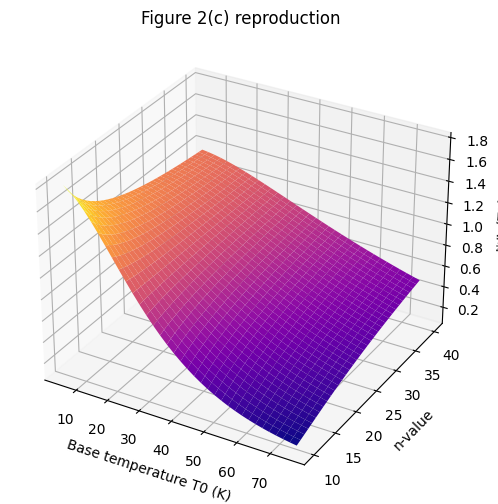

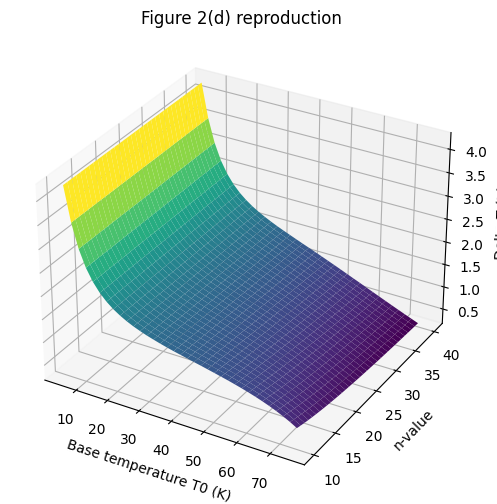

In [135]:

fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(
    T0_grid,
    param_grid,
    Iratio,
    cmap='plasma',
    edgecolor='none'
)

ax.set_xlabel("Base temperature T0 (K)")
ax.set_ylabel(ylabel)
ax.set_zlabel("I*/Ic(T0)")

if MODE == "n":
    ax.set_title("Figure 2(c) reproduction")
else:
    ax.set_title("Figure 2(a) reproduction")

plt.show()



fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(
    T0_grid,
    param_grid,
    DeltaT,
    cmap='viridis',
    edgecolor='none'
)

ax.set_xlabel("Base temperature T0 (K)")
ax.set_ylabel(ylabel)
ax.set_zlabel("Delta T (K)")

if MODE == "n":
    ax.set_title("Figure 2(d) reproduction")
else:
    ax.set_title("Figure 2(b) reproduction")

plt.show()
